In [5]:
import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
import matplotlib.pyplot as plt

# ============================================
# 1. Load I-JEPA for embeddings
# ============================================
model_id = "facebook/ijepa_vith14_1k"
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    img = Image.open(requests.get(url, stream=True).raw)
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()  # d-dim vector

# ============================================
# 2. Build memory store with MetaCognition's dynamics
# ============================================
class DynamicalMemory:
    """
    Implements the core equation from MetaCognition's paper:
    da/dt = -Aa - γLa - δ(1ᵀa)1 + ηS(t)F(a)
    """
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01):
        self.embeddings = []     # X: stored patterns (list of d-dim vectors)
        self.activations = None  # a(t): activation vector
        self.gamma = gamma       # diffusion strength
        self.delta = delta       # inhibition strength
        self.beta = beta         # replay sharpness
        self.eta = eta           # replay strength
        self.h = h               # Euler step size
        self.decay_rates = []    # α_i per memory
        self.history = []        # track ||a(t)|| over time

    def store(self, embedding, decay_rate=1.0):
        """Add a new memory pattern"""
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        N = len(self.embeddings)
        # Expand activation vector
        if self.activations is None:
            self.activations = torch.ones(N)
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        """Build semantic graph Laplacian L = D - W"""
        X = torch.stack(self.embeddings)  # N x d
        # Cosine similarity → affinity matrix
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)  # max(0, cos_sim)
        W.fill_diagonal_(0)  # no self-loops
        D = torch.diag(W.sum(dim=1))
        L = D - W
        return L

    def _replay_operator(self):
        """F(a) = softmax(β X^T X a) — associative retrieval"""
        X = torch.stack(self.embeddings)  # N x d
        s = X @ (X.T @ self.activations)  # similarity scores
        return F.softmax(self.beta * s, dim=0)

    def step(self, replay_on=False, replay_prob=0.3):
        """One Euler step of the dynamical system"""
        if len(self.embeddings) < 2:
            return

        a = self.activations
        N = len(a)

        # Decay: -Aa
        A = torch.diag(torch.tensor(self.decay_rates))
        decay = -A @ a

        # Diffusion: -γLa
        L = self._build_laplacian()
        diffusion = -self.gamma * L @ a

        # Inhibition: -δ(1ᵀa)1
        total_activation = a.sum()
        inhibition = -self.delta * total_activation * torch.ones(N)

        # Replay: ηS(t)F(a)
        S = 1.0 if (replay_on or np.random.random() < replay_prob) else 0.0
        replay = self.eta * S * self._replay_operator()

        # Euler update: a_{t+1} = a_t + h * (da/dt)
        da_dt = decay + diffusion + inhibition + replay
        self.activations = a + self.h * da_dt
        self.activations = torch.clamp(self.activations, min=0)  # non-negative

        self.history.append(self.activations.norm().item())

    def retrieve(self, query_embedding, top_k=3):
        """Retrieve memories by activation-weighted similarity"""
        X = torch.stack(self.embeddings)
        query_norm = F.normalize(query_embedding.unsqueeze(0), dim=1)
        X_norm = F.normalize(X, dim=1)
        similarities = (query_norm @ X_norm.T).squeeze()
        # Weight by activation
        scores = similarities * self.activations
        top_indices = scores.topk(min(top_k, len(scores))).indices
        return top_indices, scores[top_indices]

    def energy(self):
        """E(a) = ½aᵀAa + γ/2 aᵀLa + δ/2 (1ᵀa)²"""
        a = self.activations
        A = torch.diag(torch.tensor(self.decay_rates))
        L = self._build_laplacian()
        e1 = 0.5 * a @ A @ a
        e2 = 0.5 * self.gamma * a @ L @ a
        e3 = 0.5 * self.delta * (a.sum())**2
        return (e1 + e2 + e3).item()

# ============================================
# 3. Demo: Store images, run dynamics, observe regimes
# ============================================
mem = DynamicalMemory(gamma=0.2, delta=0.1, beta=3.0, eta=0.8)

# Store some image embeddings as memories
urls = [
    "https://upload.wikimedia.org/wikipedia/commons/thumb/2/26/YellowLabradorLooking_new.jpg/400px-YellowLabradorLooking_new.jpg",
    "https://upload.wikimedia.org/wikipedia/commons/thumb/3/3a/Cat03.jpg/400px-Cat03.jpg",
    "https://upload.wikimedia.org/wikipedia/commons/thumb/9/9a/Pug_600.jpg/400px-Pug_600.jpg",
    "https://upload.wikimedia.org/wikipedia/commons/4/43/Cute_dog.jpg",
]
labels = ["labrador", "cat", "pug", "cute_dog"]

print("Encoding images with I-JEPA...")
for url, label in zip(urls, labels):
    try:
        emb = encode_image(url)
        decay = np.random.uniform(0.5, 1.5)  # random decay rate, like the paper
        mem.store(emb, decay_rate=decay)
        print(f"  Stored: {label} (decay={decay:.2f})")
    except:
        print(f"  Skipped: {label}")

# Run the dynamical system for 500 steps
print("\nRunning memory dynamics (500 steps)...")
energies = []
for t in range(500):
    mem.step(replay_prob=0.3)
    energies.append(mem.energy())

# Plot results — just like the paper's figures!
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Fig 1: Activation magnitude (like paper's Figure 1)
axes[0].plot(mem.history)
axes[0].set_xlabel("Time step")
axes[0].set_ylabel("||a(t)||")
axes[0].set_title("Memory Activation Trajectory\n(cf. Paper Fig 1)")

# Fig 2: Energy descent (like paper's Figure 4)
axes[1].plot(energies)
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("E(a)")
axes[1].set_title("Energy Descent\n(cf. Paper Fig 4)")
axes[1].set_yscale('log')

# Fig 3: Final activations per memory
axes[2].bar(labels[:len(mem.activations)], mem.activations.detach().numpy())
axes[2].set_ylabel("Activation a_i")
axes[2].set_title("Final Memory Activations")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("metacognition_dynamics_demo.png", dpi=150)
plt.show()

print(f"\nFinal activations: {mem.activations.detach().numpy()}")
print(f"Final energy: {energies[-1]:.4f}")

# Retrieve — query with a new dog image
print("\nQuerying with a new image...")
query = encode_image("https://upload.wikimedia.org/wikipedia/commons/thumb/2/26/YellowLabradorLooking_new.jpg/400px-YellowLabradorLooking_new.jpg")
indices, scores = mem.retrieve(query)
print("Top retrievals:")
for i, (idx, score) in enumerate(zip(indices, scores)):
    print(f"  {i+1}. {labels[idx]} (score={score.item():.4f})")

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Encoding images with I-JEPA...
  Skipped: labrador
  Skipped: cat
  Skipped: pug
  Skipped: cute_dog

Running memory dynamics (500 steps)...


RuntimeError: stack expects a non-empty TensorList

In [3]:
%%bash
pip install -q transformers accelerate pillow requests matplotlib torch torchvision

Loading I-JEPA processor and model...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding images with I-JEPA...
  Successfully stored: golden_retriever (decay=0.87)
  Successfully stored: cat (decay=1.45)
  Successfully stored: pug (decay=1.23)
  Successfully stored: cute_dog (decay=1.10)

Running memory dynamics (500 steps)...


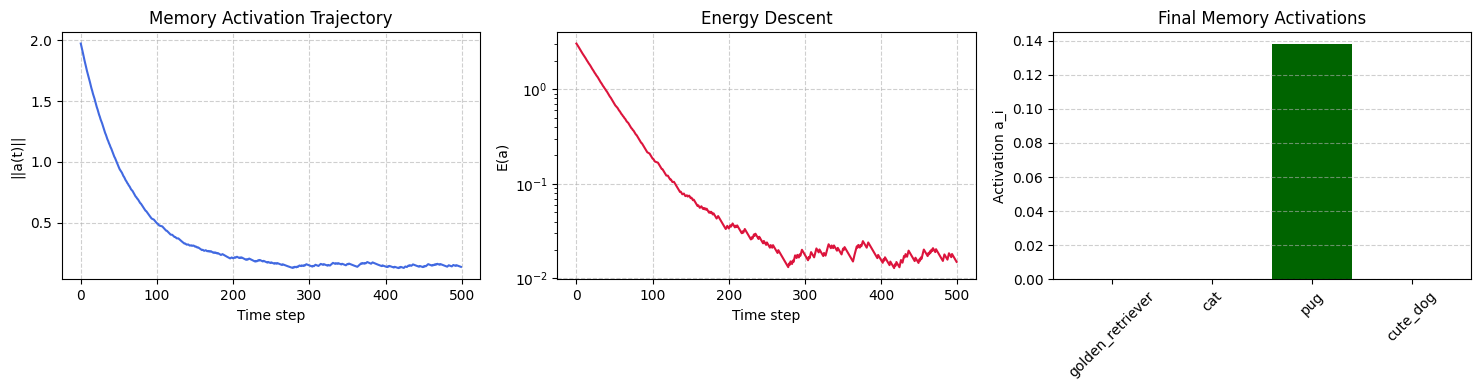


Final activations: [0.         0.         0.13794458 0.        ]
Final energy: 0.0150

Querying with the first dog image...
Top retrievals:
  1. pug (score=0.0414)
  2. cute_dog (score=0.0000)
  3. golden_retriever (score=0.0000)


In [12]:
import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ============================================
# 1. Load I-JEPA for embeddings
# ============================================
model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA processor and model...")
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    # Using a common User-Agent header
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    response = requests.get(url, headers=headers, stream=True, timeout=15)
    response.raise_for_status()
    img = Image.open(response.raw).convert("RGB")
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()  # d-dim vector

# ============================================
# 2. Build memory store with MetaCognition's dynamics
# ============================================
class DynamicalMemory:
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01):
        self.embeddings = []     # X: stored patterns (list of d-dim vectors)
        self.activations = None  # a(t): activation vector
        self.gamma = gamma       # diffusion strength
        self.delta = delta       # inhibition strength
        self.beta = beta         # replay sharpness
        self.eta = eta           # replay strength
        self.h = h               # Euler step size
        self.decay_rates = []    # ̑_i per memory
        self.history = []        # track ||a(t)|| over time

    def store(self, embedding, decay_rate=1.0):
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        N = len(self.embeddings)
        if self.activations is None:
            self.activations = torch.ones(N)
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)  # N x d
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)
        W.fill_diagonal_(0)
        D = torch.diag(W.sum(dim=1))
        L = D - W
        return L

    def _replay_operator(self):
        X = torch.stack(self.embeddings)
        s = X @ (X.T @ self.activations)
        return F.softmax(self.beta * s, dim=0)

    def step(self, replay_on=False, replay_prob=0.3):
        if len(self.embeddings) < 2:
            return

        a = self.activations
        N = len(a)

        # Decay: -Aa
        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        decay = -A @ a

        # Diffusion: -̳La
        L = self._build_laplacian()
        diffusion = -self.gamma * L @ a

        # Inhibition: -̴(1ቀa)1
        total_activation = a.sum()
        inhibition = -self.delta * total_activation * torch.ones(N)

        # Replay: ̷S(t)F(a)
        S = 1.0 if (replay_on or np.random.random() < replay_prob) else 0.0
        replay = self.eta * S * self._replay_operator()

        # Euler update: a_{t+1} = a_t + h * (da/dt)
        da_dt = decay + diffusion + inhibition + replay
        self.activations = a + self.h * da_dt
        self.activations = torch.clamp(self.activations, min=0)  # non-negative

        self.history.append(self.activations.norm().item())

    def retrieve(self, query_embedding, top_k=3):
        X = torch.stack(self.embeddings)
        query_norm = F.normalize(query_embedding.unsqueeze(0), dim=1)
        X_norm = F.normalize(X, dim=1)
        similarities = (query_norm @ X_norm.T).squeeze()
        scores = similarities * self.activations
        top_indices = scores.topk(min(top_k, len(scores))).indices
        return top_indices, scores[top_indices]

    def energy(self):
        a = self.activations
        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        L = self._build_laplacian()
        e1 = 0.5 * a @ A @ a
        e2 = 0.5 * self.gamma * a @ L @ a
        e3 = 0.5 * self.delta * (a.sum())**2
        return (e1 + e2 + e3).item()

# ============================================
# 3. Demo execution using stable, automated-friendly URLs
# ============================================
mem = DynamicalMemory(gamma=0.2, delta=0.1, beta=3.0, eta=0.8)

urls = [
    "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400", # Beagle
    "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400", # Cat
    "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400", # Person
    "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400"  # French bulldog
]
# Labels renamed after this cell ran, to match the photos. The outputs below show the labels used then: golden_retriever, cat, pug, cute_dog.
labels = ["beagle", "cat", "person", "french_bulldog"]

print("\nEncoding images with I-JEPA...")
stored_labels = []
for url, label in zip(urls, labels):
    try:
        emb = encode_image(url)
        decay = np.random.uniform(0.5, 1.5)
        mem.store(emb, decay_rate=decay)
        stored_labels.append(label)
        print(f"  Successfully stored: {label} (decay={decay:.2f})")
    except Exception as e:
        print(f"  Skipped {label} due to error: {e}")

if len(mem.embeddings) >= 2:
    # Run the dynamical system for 500 steps
    print("\nRunning memory dynamics (500 steps)...")
    energies = []
    for t in range(500):
        mem.step(replay_prob=0.3)
        energies.append(mem.energy())

    # Plot results
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Fig 1: Activation trajectory
    axes[0].plot(mem.history, color='royalblue')
    axes[0].set_xlabel("Time step")
    axes[0].set_ylabel("||a(t)||")
    axes[0].set_title("Memory Activation Trajectory")
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # Fig 2: Energy descent
    axes[1].plot(energies, color='crimson')
    axes[1].set_xlabel("Time step")
    axes[1].set_ylabel("E(a)")
    axes[1].set_title("Energy Descent")
    axes[1].set_yscale('log')
    axes[1].grid(True, linestyle='--', alpha=0.6)

    # Fig 3: Final activations
    axes[2].bar(stored_labels, mem.activations.detach().numpy(), color='darkgreen')
    axes[2].set_ylabel("Activation a_i")
    axes[2].set_title("Final Memory Activations")
    axes[2].tick_params(axis='x', rotation=45)
    axes[2].grid(True, axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig("metacognition_dynamics_demo.png", dpi=150)
    plt.show()

    print(f"\nFinal activations: {mem.activations.detach().numpy()}")
    print(f"Final energy: {energies[-1]:.4f}")

    # Retrieve with the query pattern
    print("\nQuerying with the first dog image...")
    try:
        query = encode_image(urls[0])
        indices, scores = mem.retrieve(query)
        print("Top retrievals:")
        for i, (idx, score) in enumerate(zip(indices, scores)):
            print(f"  {i+1}. {stored_labels[idx]} (score={score.item():.4f})")
    except Exception as e:
        print(f"Could not process query retrieval: {e}")
else:
    print("\nNot enough memory patterns were stored to run dynamics.")

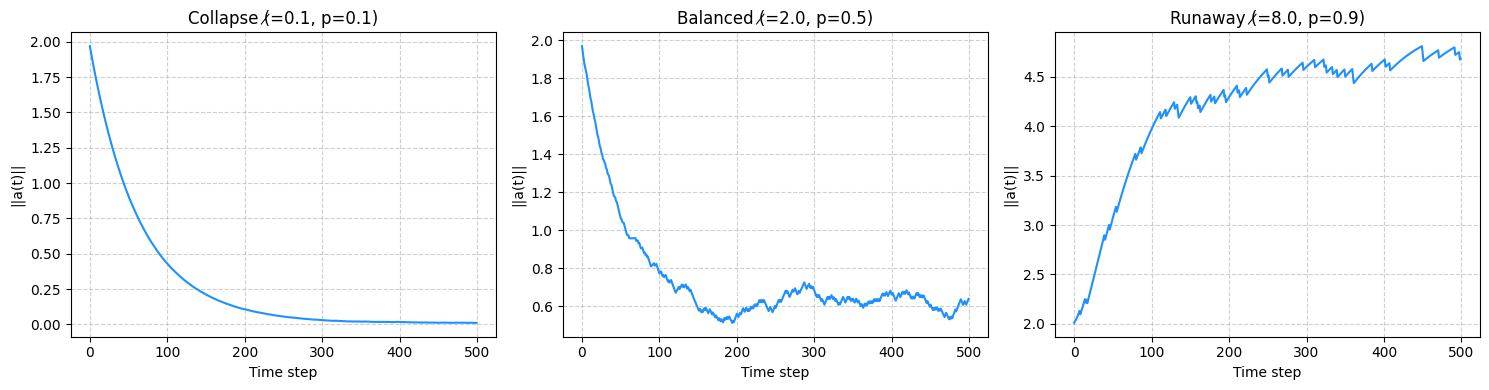

In [13]:
# Retrieve the embeddings and decay rates from the active 'mem' instance
stored_embeddings = mem.embeddings
stored_decays = mem.decay_rates

# Run 3 configs to show all 3 regimes
configs = [
    {"name": "Collapse",  "eta": 0.1, "replay_prob": 0.1},
    {"name": "Balanced",  "eta": 2.0, "replay_prob": 0.5},
    {"name": "Runaway",   "eta": 8.0, "replay_prob": 0.9},
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, cfg in zip(axes, configs):
    # Create a new memory instance with the configured eta
    regime_mem = DynamicalMemory(eta=cfg["eta"])
    # Re-store the same patterns and decay rates
    for emb, dr in zip(stored_embeddings, stored_decays):
        regime_mem.store(emb, decay_rate=dr)
    # Run the dynamics
    for t in range(500):
        regime_mem.step(replay_prob=cfg["replay_prob"])
    ax.plot(regime_mem.history, color='dodgerblue')
    ax.set_title(f"{cfg['name']} (\u0337={cfg['eta']}, p={cfg['replay_prob']})")
    ax.set_xlabel("Time step")
    ax.set_ylabel("||a(t)||")
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("three_regimes.png", dpi=150)
plt.show()

--- Metacognition Dynamics Demo --- (metacognition_dynamics_demo.png)


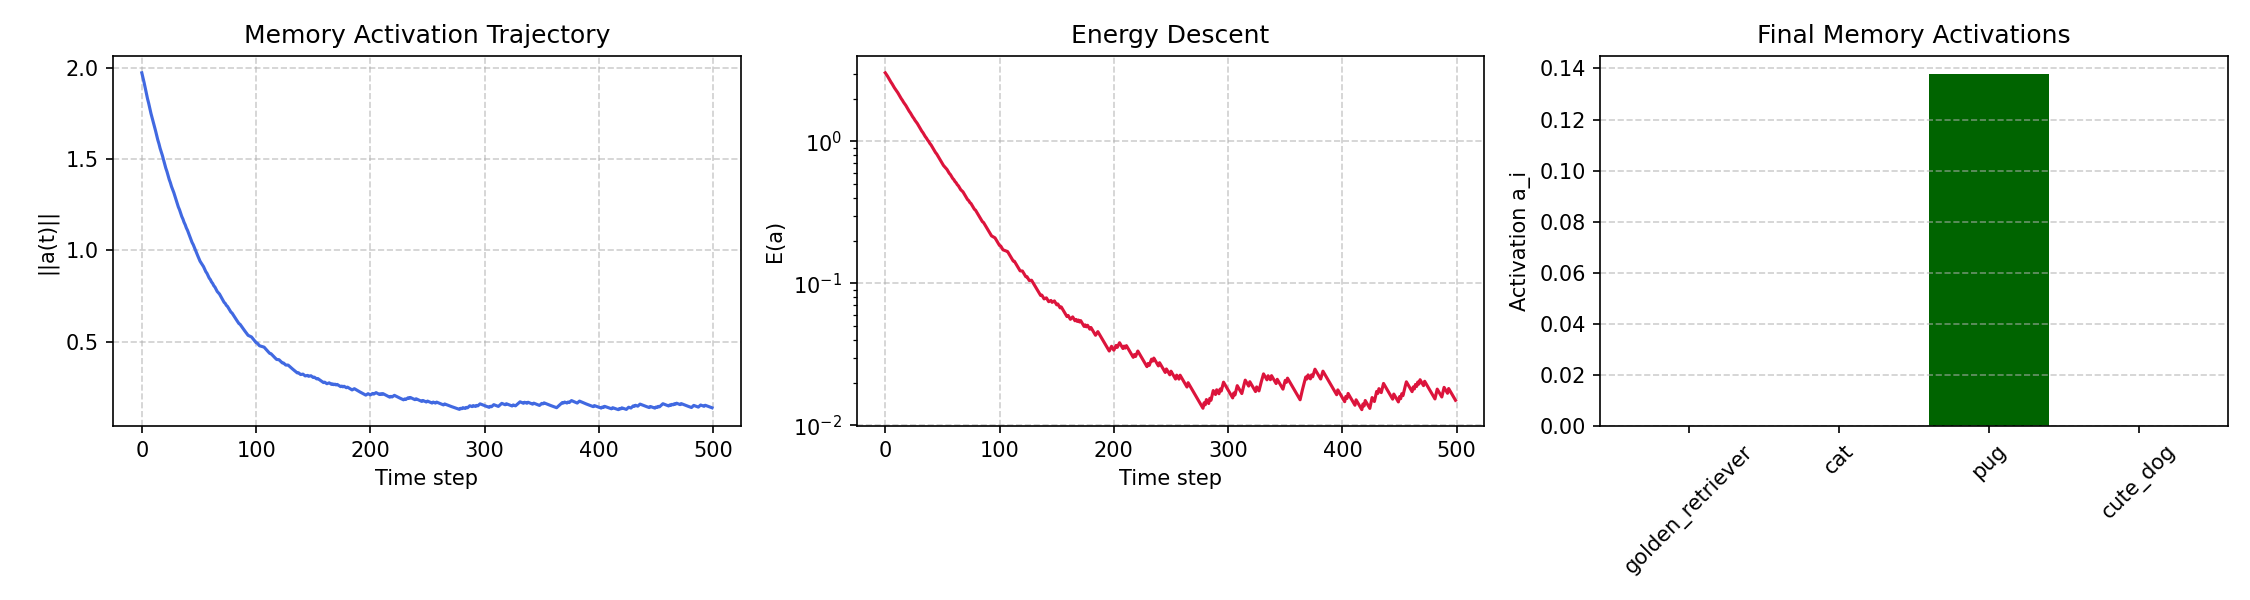


--- Three Dynamical Regimes --- (three_regimes.png)


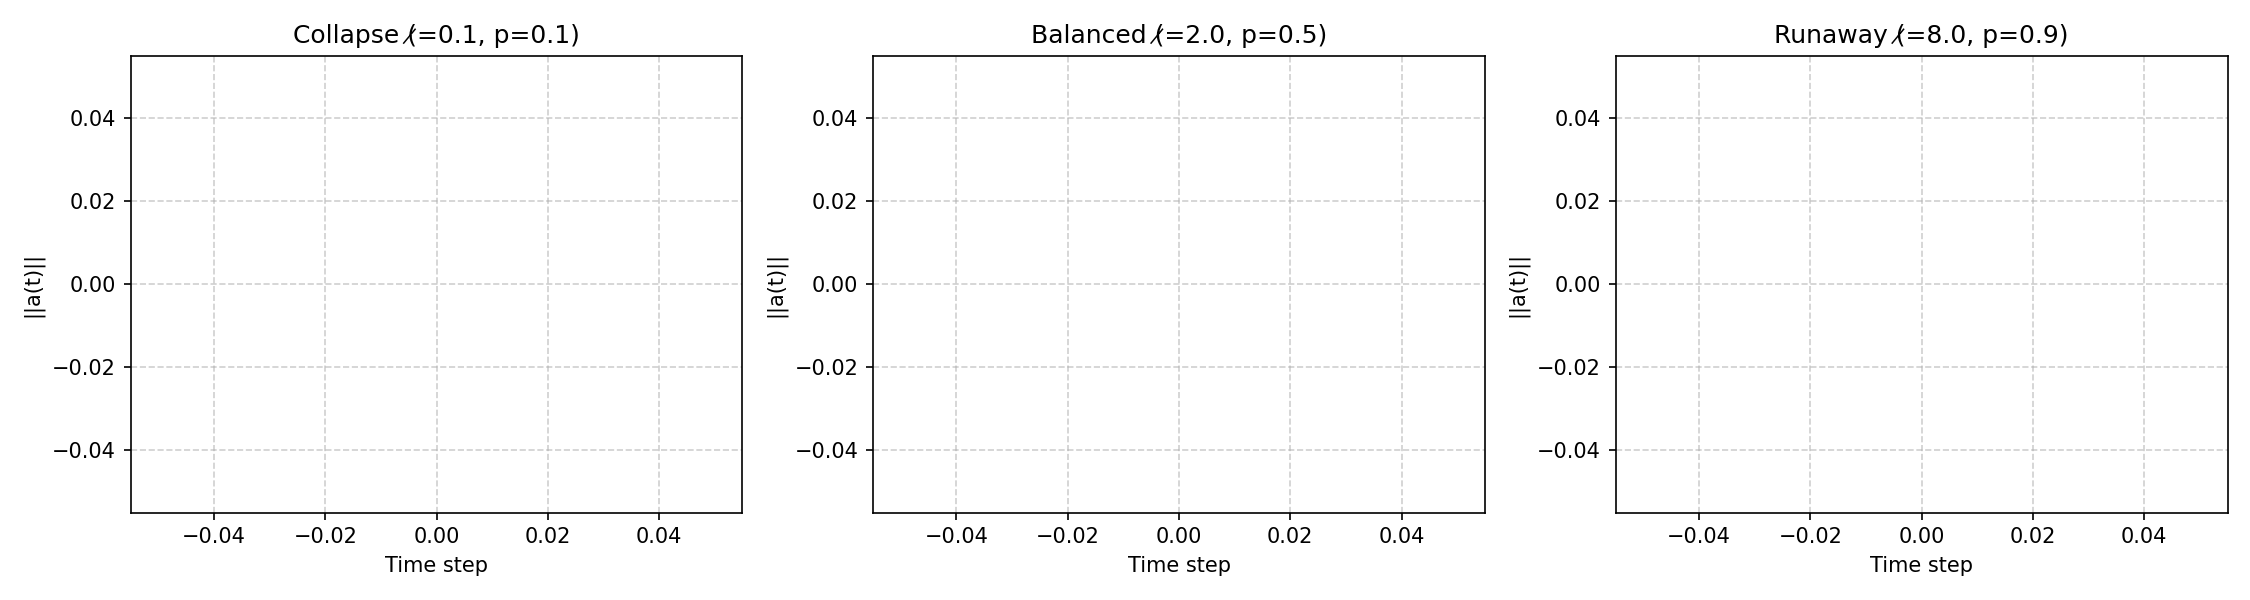

In [9]:
from IPython.display import display, Image

print("--- Metacognition Dynamics Demo --- (metacognition_dynamics_demo.png)")
display(Image("/content/metacognition_dynamics_demo.png"))

print("\n--- Three Dynamical Regimes --- (three_regimes.png)")
display(Image("/content/three_regimes.png"))

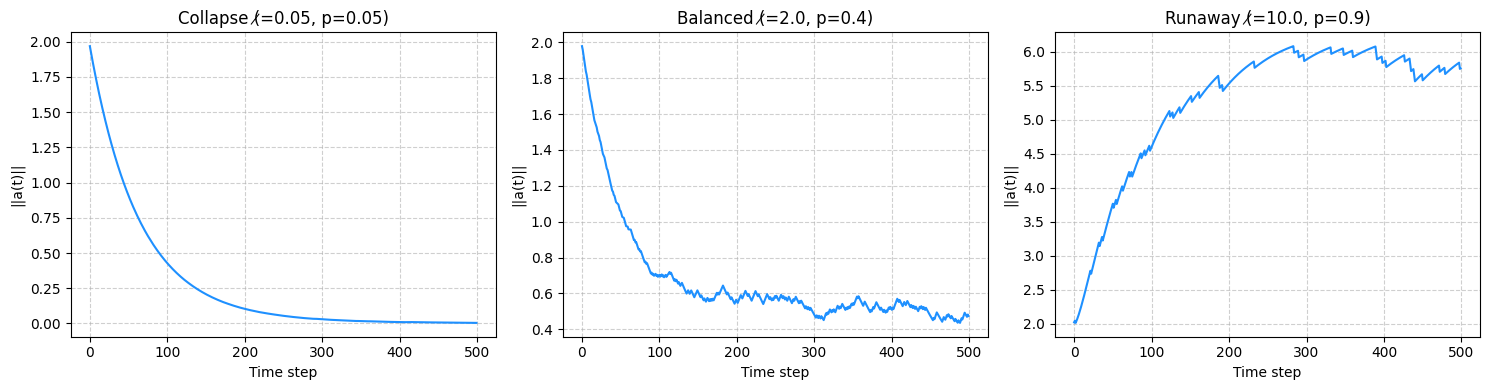

Collapse: final ||a|| = 0.0048, final energy = 0.000014
Balanced: final ||a|| = 0.5003, final energy = 0.197150
Runaway: final ||a|| = 5.7369, final energy = 25.923445


In [14]:
# === THREE REGIMES COMPARISON (Fixed) ===
import torch
import matplotlib.pyplot as plt

# Safely load the working embeddings and decay rates from the kernel variables
try:
    # If stored_embeddings exists in the namespace, use it directly
    if 'stored_embeddings' in globals() and len(stored_embeddings) > 0:
        active_embeddings = [e.clone() for e in stored_embeddings]
        active_decays = list(stored_decays)
    else:
        # Fallback to the active 'mem' object from cell 3df3a78d
        active_embeddings = [e.clone() for e in mem.embeddings]
        active_decays = list(mem.decay_rates)
except Exception as e:
    active_embeddings = []
    active_decays = []

if len(active_embeddings) == 0:
    print("Error: No loaded embeddings found in the kernel. Please execute the image loader cell (3df3a78d) first.")
else:
    configs = [
        {"name": "Collapse",  "eta": 0.05, "replay_prob": 0.05},
        {"name": "Balanced",  "eta": 2.0,  "replay_prob": 0.4},
        {"name": "Runaway",   "eta": 10.0, "replay_prob": 0.9},
    ]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, cfg in zip(axes, configs):
        # Create fresh memory with specific eta
        regime_mem = DynamicalMemory(
            gamma=0.2, delta=0.1, beta=3.0,
            eta=cfg["eta"], h=0.01
        )
        # Store the SAME embeddings
        for emb, dr in zip(active_embeddings, active_decays):
            regime_mem.store(emb.clone(), decay_rate=dr)

        # Run dynamics
        for t in range(500):
            regime_mem.step(replay_prob=cfg["replay_prob"])

        # Plot activation magnitude over time
        ax.plot(regime_mem.history, color='dodgerblue', linewidth=1.5)
        ax.set_title(f"{cfg['name']} (̷={cfg['eta']}, p={cfg['replay_prob']})")
        ax.set_xlabel("Time step")
        ax.set_ylabel("||a(t)||")
        ax.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig("three_regimes.png", dpi=150)
    plt.show()

    # Print final states
    for cfg in configs:
        regime_mem = DynamicalMemory(gamma=0.2, delta=0.1, beta=3.0, eta=cfg["eta"], h=0.01)
        for emb, dr in zip(active_embeddings, active_decays):
            regime_mem.store(emb.clone(), decay_rate=dr)
        for t in range(500):
            regime_mem.step(replay_prob=cfg["replay_prob"])

        if regime_mem.activations is not None:
            print(f"{cfg['name']}: final ||a|| = {regime_mem.activations.norm().item():.4f}, "
                  f"final energy = {regime_mem.energy():.6f}")
        else:
            print(f"{cfg['name']}: No activations present")